# Figures du rapport (style article IEEE)

Figures du rapport du *First EurAAP Small Antenna Super-Gain Challenge*, en anglais, en PNG (300 dpi) et en PDF
vectoriel, dans `PUBLICATIONS/…/rapport/figures/`. **Aucune simulation** : toutes les valeurs sont lues dans les
fichiers de résultats (CST, MoM, campagnes, adaptation). Le seul calcul est celui, circuit, du réseau d'adaptation
(`solver.optim.matching`), à partir des données CST et Johanson.

`figures_index.md` (écrit à la fin) donne pour chaque figure sa source de données et une légende proposée.
La dernière section liste les contrôles de cohérence entre fichiers.

In [1]:
%matplotlib inline
import csv, json, os, re, sys
from pathlib import Path

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'solver' / 'optim').is_dir())
HERE = ROOT / 'solver' / 'antenna_simulation' / 'euraap_challenge'
for p in (str(ROOT), str(HERE)):
    if p not in sys.path:
        sys.path.insert(0, p)
import compare_v5 as cv
import match_from_cst as mfc
from solver.optim import matching as mt
from solver.optim.components import JOHANSON_R14S_RF_1GHZ, johanson_r14s_model
from solver.optim.loss_model import alpha_calibrated

BASE = Path(os.environ.get('CHALLENGE_DIR',
                           r'D:\PhD_Fahdilou_Leat\PUBLICATIONS\7-EurAAP Small Antenna Super-Gain Challenge'))
V6_DIR, V5_DIR = BASE / 'fiches_cst' / 'resultats_V6', BASE / 'fiches_cst' / 'resultats_V5'
EXPL_DIR, NOTES_DIR = BASE / 'exploration', BASE / 'notes_comprehension'
SWEEP_DIR = V6_DIR / 'V6b_balayage_X'
FINAL_DIR = SWEEP_DIR / 'X=76.25'
FIG_DIR = BASE / 'rapport' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
F0 = 1.0e9


def read_json(p):
    return json.loads(Path(p).read_text(encoding='utf-8'))


def read_jsonl(p):
    return [json.loads(l) for l in open(p, encoding='utf-8') if l.strip()]


def read_csv(p):
    def num(v):
        try:
            return float(v)
        except ValueError:
            return {'True': True, 'False': False}.get(v, v)
    with open(p, newline='', encoding='utf-8') as fh:
        return [{k: num(v) for k, v in r.items()} for r in csv.DictReader(fh)]


def cst_params(path):
    # {name: float} from the 'Parameters = {...}' line of a CST export
    txt = Path(path).read_text(encoding='utf-8', errors='replace')
    m = re.search(r'Parameters = \{([^}]*)\}', txt)
    return {k.strip(): float(v) for k, v in (kv.split('=') for kv in m.group(1).split(';') if '=' in kv)}


def cut_value(path, phi_deg, col='Abs(Phi)'):
    # value of a CST far-field cut theta = 90 deg at phi = phi_deg
    d = cv.read_cst_farfield(path)
    k = int(np.argmin(np.abs(d['Phi'] - phi_deg)))
    assert abs(d['Phi'][k] - phi_deg) < 1e-6, (path, phi_deg)
    return float(d[col][k])


def cuts_by_freq(folder):
    # {f_GHz: path} of the cuts theta = 90 deg in a CST result folder
    out = {}
    for p in Path(folder).glob('*farfield_cut_theta=90_f=*GHz.txt'):
        out[float(re.search(r'f=([0-9.]+)GHz', p.name).group(1))] = p
    return dict(sorted(out.items()))


def read_dxf_polylines(path):
    lines = [l.strip() for l in open(path, encoding='utf-8', errors='replace')]
    polys, cur, mode, xy = [], None, None, None
    for code_, val in zip(lines[0::2], lines[1::2]):
        if code_ == '0':
            mode = val
            if val == 'POLYLINE':
                cur = dict(layer=None, pts=[]); polys.append(cur)
            elif val == 'VERTEX':
                xy = {}; cur['pts'].append(xy)
        elif code_ == '8' and mode == 'POLYLINE':
            cur['layer'] = val
        elif code_ in ('10', '20') and mode == 'VERTEX':
            xy[code_] = float(val)
    out = []
    for q in polys:
        xs = [v['10'] for v in q['pts']]; ys = [v['20'] for v in q['pts']]
        out.append(dict(layer=q['layer'], xmin=min(xs), xmax=max(xs), ymin=min(ys), ymax=max(ys)))
    return out


def rel(p):
    p = Path(p)
    try:
        return str(p.relative_to(BASE)).replace('\\', '/')
    except ValueError:
        try:
            return 'repo: ' + str(p.relative_to(ROOT)).replace('\\', '/')
        except ValueError:
            return str(p)


# --- coherence log --------------------------------------------------------------------------------
COHERENCE = []


def check(name, a, b, tol, unit=''):
    d = float(np.max(np.abs(np.asarray(a, dtype=complex) - np.asarray(b, dtype=complex))))
    COHERENCE.append(dict(name=name, a=a, b=b, diff=d, tol=tol, unit=unit, ok=bool(d <= tol)))
    return d <= tol


# --- IEEE style -----------------------------------------------------------------------------------
COL1, COL2 = 3.5, 7.16                       # IEEE single / double column width (in)
BLUE, ORANGE, GREEN, GREY, BLACK = '#1f5fb4', '#d1531c', '#2a8a4a', '#7a7a7a', '#000000'
COPPER, SUBSTRATE = '#b87333', '#e9eef2'
mpl.rcParams.update({
    'font.family': 'serif', 'font.serif': ['Times New Roman', 'Times', 'DejaVu Serif'], 'mathtext.fontset': 'stix',
    'font.size': 8, 'axes.labelsize': 8, 'axes.titlesize': 8, 'legend.fontsize': 7, 'xtick.labelsize': 7,
    'ytick.labelsize': 7, 'axes.linewidth': 0.6, 'lines.linewidth': 1.0, 'lines.markersize': 3.5,
    'xtick.direction': 'in', 'ytick.direction': 'in', 'xtick.major.width': 0.6, 'ytick.major.width': 0.6,
    'axes.grid': True, 'grid.color': '#d9d9d9', 'grid.linewidth': 0.4, 'legend.frameon': False,
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white',
    'figure.dpi': 150, 'pdf.fonttype': 42, 'ps.fonttype': 42, 'axes.spines.top': True, 'axes.spines.right': True})
INDEX = []


def save(fig, name, caption, sources):
    fig.savefig(FIG_DIR / f'{name}.png', dpi=300, bbox_inches='tight', pad_inches=0.02)
    fig.savefig(FIG_DIR / f'{name}.pdf', bbox_inches='tight', pad_inches=0.02)
    INDEX.append(dict(name=name, caption=caption, sources=[rel(s) for s in sources]))
    plt.show()


def panel(ax, letter):
    ax.text(0.0, 1.02, f'({letter})', transform=ax.transAxes, ha='left', va='bottom', fontsize=8, fontweight='bold')


def db(x):
    return 10 * np.log10(np.asarray(x, float))


S1P_FINAL = next(FINAL_DIR.glob('*.s1p'))
P_FINAL = cst_params(S1P_FINAL)
ADAPT = read_json(FINAL_DIR / 'adaptation_from_cst_johanson.json')
B3P = read_json(V6_DIR / 'V6_parametres_B3_1.00GHz.json')
print(f"final CST case: {S1P_FINAL.name}, X = {P_FINAL['X']} mm; adaptation generated {ADAPT['generated']} "
      f"(recommended rank {ADAPT['recommended_rank']})")

final CST case: Reseau end-fire_76.25.s1p, X = 76.25 mm; adaptation generated 2026-11-08T23:24:15 (recommended rank 2)


## Fig. 1 — Géométrie finale

Positions en y et gap lus dans `V6b/V6b.dxf` (export CST) ; demi-longueur X lue dans l'en-tête du `.s1p` du cas
final ; charges (Cap1 / Cap2) et leur ruban lus dans les mêmes paramètres CST ; boîte dans
`notes_comprehension/01_sujet_et_contraintes.md`.

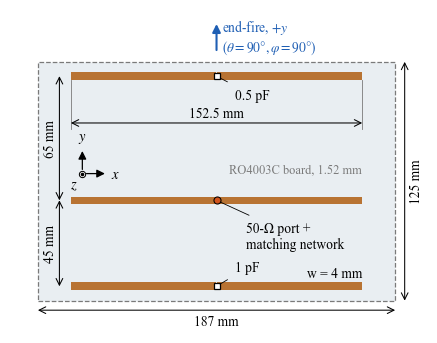

In [2]:
spec = (NOTES_DIR / '01_sujet_et_contraintes.md').read_text(encoding='utf-8')
grab = lambda pat: float(re.search(pat, spec).group(1))
W_BOX, L_BOX, H_BOX = (grab(r'Largeur \$W\$ \(axe x\) \| ≤ (\d+) mm'), grab(r'Longueur \$L\$ \(axe y\) \| ≤ (\d+) mm'),
                       grab(r'Hauteur \$H\$ \(axe z\) \| ≤ (\d+) mm'))
DXF = V6_DIR / 'V6b' / 'V6b.dxf'
polys = read_dxf_polylines(DXF)
cu = [p for p in polys if p['layer'].upper().startswith('COPPER')]
sub = next(p for p in polys if 'RO4003' in p['layer'].upper())
P_V6B = cst_params(next((V6_DIR / 'V6b').glob('*.s1p')))
check('DXF V6b : bout des bras = X du .s1p V6b', max(p['xmax'] for p in cu), P_V6B['X'], 1e-9, 'mm')
X_HALF, GAP_HALF = P_FINAL['X'], min(p['xmin'] for p in cu if p['xmin'] > 0)
check('DXF : demi-gap = paramètre CST gap', GAP_HALF, P_FINAL['gap'], 1e-9, 'mm')
y_ranges = sorted({(p['ymin'], p['ymax']) for p in cu})
yc = np.array([(a + b) / 2 for a, b in y_ranges]); w_strip = y_ranges[0][1] - y_ranges[0][0]
check('DXF : centres des rubans = paramètres B3 (MoM)', sorted(yc),
      sorted(s['y_center_mm']['value'] for s in B3P['strips']), 1e-6, 'mm')
check('DXF : substrat = boîte (x, y)', [sub['xmax'] - sub['xmin'], sub['ymax'] - sub['ymin']], [W_BOX, L_BOX], 1e-9, 'mm')
check('DXF : largeur des rubans = 2 Y (CST)', w_strip, 2 * P_FINAL['Y'], 1e-9, 'mm')

def strip_of(pos):
    return next(i for i, (a, b) in enumerate(y_ranges) if a - 1e-9 <= pos <= b + 1e-9)
loads = {strip_of(P_FINAL['Pos_el1']): P_FINAL['Cap1'], strip_of(P_FINAL['Pos_el3']): P_FINAL['Cap2']}
fed = strip_of(P_FINAL['Pos_el2'])
sol = ADAPT['solutions'][ADAPT['recommended_rank'] - 1]
net_txt = ' / '.join(f"{e['label']}" for e in sol['elements_port_to_gap'])

fig, ax = plt.subplots(figsize=(COL1, 3.05))
ax.add_patch(Rectangle((sub['xmin'], sub['ymin']), sub['xmax'] - sub['xmin'], sub['ymax'] - sub['ymin'],
                       fc=SUBSTRATE, ec=GREY, lw=0.6, ls='--', zorder=0))
for i, (a, b) in enumerate(y_ranges):
    for x0, x1 in ((-X_HALF, -GAP_HALF), (GAP_HALF, X_HALF)):
        ax.add_patch(Rectangle((x0, a), x1 - x0, b - a, fc=COPPER, ec='none', zorder=2))
    yy = (a + b) / 2
    if i in loads:
        ax.plot(0, yy, marker='s', ms=3.2, mfc='white', mec=BLACK, mew=0.6, zorder=3)
        ax.annotate(f'{loads[i] * 1e12:g} pF', (0, yy), xytext=(9, (-9 if yy > 0 else 9)), textcoords='offset points',
                    fontsize=6.5, ha='left', va='center', arrowprops=dict(arrowstyle='-', lw=0.4))
    if i == fed:
        ax.plot(0, yy, marker='o', ms=3.4, mfc=ORANGE, mec=BLACK, mew=0.5, zorder=3)
        ax.annotate('50-Ω port +\nmatching network', (0, yy), xytext=(14, -10), textcoords='offset points',
                    fontsize=6.5, ha='left', va='top', arrowprops=dict(arrowstyle='-', lw=0.4))
# dimensions
def dim(x0, y0, x1, y1, text, off=(0, 0), rot=0, ha='center', va='center'):
    ax.annotate('', (x0, y0), (x1, y1), arrowprops=dict(arrowstyle='<->', lw=0.5, shrinkA=0, shrinkB=0))
    ax.text((x0 + x1) / 2 + off[0], (y0 + y1) / 2 + off[1], text, fontsize=6.5, rotation=rot, ha=ha, va=va)
y_len = (yc[1] + yc[2]) / 2 + 8                                  # empty band between the fed and the +y strip
ax.plot([-X_HALF, -X_HALF], [y_len - 3, y_ranges[-1][0]], color=GREY, lw=0.4)
ax.plot([X_HALF, X_HALF], [y_len - 3, y_ranges[-1][0]], color=GREY, lw=0.4)
dim(-X_HALF, y_len, X_HALF, y_len, f'{2 * X_HALF:g} mm', off=(0, 1.5), va='bottom')
xl = -X_HALF - 6
dim(xl, yc[0], xl, yc[1], f'{yc[1] - yc[0]:g} mm', off=(-1.5, 0), rot=90, ha='right')
dim(xl, yc[1], xl, yc[2], f'{yc[2] - yc[1]:g} mm', off=(-1.5, 0), rot=90, ha='right')
dim(sub['xmin'], sub['ymin'] - 5, sub['xmax'], sub['ymin'] - 5, f'{W_BOX:g} mm', off=(0, -2), va='top')
dim(sub['xmax'] + 5, sub['ymin'], sub['xmax'] + 5, sub['ymax'], f'{L_BOX:g} mm', off=(2, 0), rot=90, ha='left')
ax.text(X_HALF, y_ranges[0][1] + 1.5, f'w = {w_strip:g} mm', fontsize=6.5, ha='right', va='bottom')
ax.text(X_HALF, yc[1] + 16, f'RO4003C board, {P_FINAL["e_substract"]:g} mm', fontsize=6, ha='right',
        va='center', color=GREY)
# axes and target direction
ox, oy = -X_HALF + 6, yc[1] + 14
ax.annotate('', (ox + 14, oy), (ox, oy), arrowprops=dict(arrowstyle='-|>', lw=0.6, color=BLACK))
ax.annotate('', (ox, oy + 14), (ox, oy), arrowprops=dict(arrowstyle='-|>', lw=0.6, color=BLACK))
ax.text(ox + 15, oy, '$x$', va='center', fontsize=7); ax.text(ox, oy + 15, '$y$', ha='center', va='bottom', fontsize=7)
ax.plot(ox, oy, 'o', ms=3, mfc='white', mec=BLACK, mew=0.5); ax.plot(ox, oy, '.', ms=1.5, color=BLACK)
ax.text(ox - 2.5, oy - 2.5, '$z$', ha='right', va='top', fontsize=7)
ax.annotate('', (0, sub['ymax'] + 22), (0, sub['ymax'] + 4), arrowprops=dict(arrowstyle='-|>', lw=1.0, color=BLUE))
ax.text(3, sub['ymax'] + 13, 'end-fire, $+y$\n($\\theta=90°, \\varphi=90°$)', color=BLUE, fontsize=6.5, va='center')
ax.set_xlim(sub['xmin'] - 12, sub['xmax'] + 14); ax.set_ylim(sub['ymin'] - 14, sub['ymax'] + 25)
ax.set_aspect('equal'); ax.axis('off')
save(fig, 'fig01_geometry_final',
     f"Top view of the final design (CST model, X = {X_HALF:g} mm): three copper strips "
     f"({2 * X_HALF:g} × {w_strip:g} mm, {P_FINAL['epaisseur'] * 1e3:g} µm) on a {W_BOX:g} × {L_BOX:g} × "
     f"{P_FINAL['e_substract']:g} mm RO4003C board (CST library: εr = 3.55, tan δ = 0.0027) that fills the challenge box "
     f"({W_BOX:g} × {L_BOX:g} × {H_BOX:g} mm). Centre-to-centre spacings {yc[1] - yc[0]:g} and {yc[2] - yc[1]:g} mm. "
     f"The centre-fed strip ({2 * GAP_HALF:g}-mm gap) carries the 50-Ω port and the matching network "
     f"({net_txt}, Fig. 7); the parasitic strips are loaded at their centre by "
     f"{loads[2] * 1e12:g} pF (+y) and {loads[0] * 1e12:g} pF (−y). Target: end-fire gain towards +y, φ polarisation.",
     [DXF, S1P_FINAL, NOTES_DIR / '01_sujet_et_contraintes.md', FINAL_DIR / 'adaptation_from_cst_johanson.json'])

## Fig. 2 — Méthode

Reprise de `10_methode.png` (notebook de présentation), traduite. Les temps sont ceux mesurés lors de l'exécution de
`presentation_design_B3_1GHz.ipynb` (lus dans ses sorties) ; N dans `V6_parametres_B3_1.00GHz.json` ; nombres de
géométries dans `B3_designs.jsonl` et `B4_bo_history.json`.

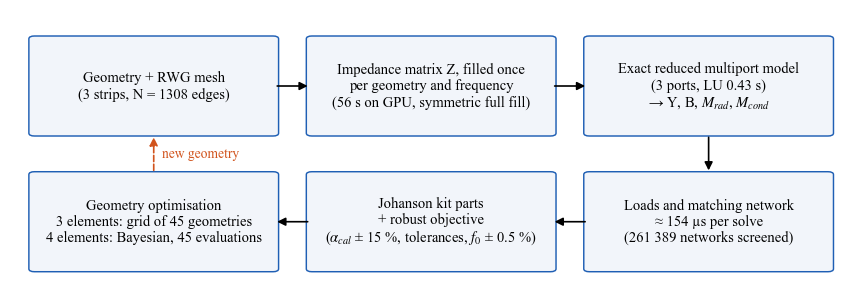

In [3]:
PRES_NB = HERE / 'presentation_design_B3_1GHz.ipynb'
pres = read_json(PRES_NB)
out_txt = ''.join(''.join(o.get('text', '')) for c in pres['cells'] if c['cell_type'] == 'code' for o in c.get('outputs', []))
def t_of(label):
    m = re.search(re.escape(label) + r'\s+([\d.]+)\s*(µs|ms|s)\b', out_txt)
    return float(m.group(1)) * {'µs': 1e-6, 'ms': 1e-3, 's': 1.0}[m.group(2)]
T_FILL, T_LU, T_SOLVE = t_of('remplissage de Z'), t_of('LU de Z_t'), t_of('un solve (charges -> G, Z_in)')
N_EDGES = B3P['mesh_check']['N_coarse']
m = re.search(r'N = (\d+) arêtes RWG', out_txt)
check('N (présentation) = N (paramètres B3)', int(m.group(1)), N_EDGES, 0)
B3 = read_jsonl(EXPL_DIR / 'B3_designs.jsonl'); B4 = read_jsonl(EXPL_DIR / 'B4_designs.jsonl')
B4_HIST = read_json(EXPL_DIR / 'B4_bo_history.json')
n_b3 = len({tuple(r['spacings_mm']) for r in B3}); n_b4 = len(B4_HIST['records'])
ADAPT6B = read_json(V6_DIR / 'V6_adaptation_B3_1.00GHz.json')
n_comb = sum(ADAPT6B['combinations_total'].values())

fig, ax = plt.subplots(figsize=(COL2, 2.35))
ax.set_xlim(0, 3); ax.set_ylim(0.05, 1.95); ax.axis('off')
boxes = [
    (0.5, 1.45, f'Geometry + RWG mesh\n(3 strips, N = {N_EDGES} edges)'),
    (1.5, 1.45, f'Impedance matrix Z, filled once\nper geometry and frequency\n({T_FILL:.0f} s on GPU, symmetric full fill)'),
    (2.5, 1.45, f'Exact reduced multiport model\n(3 ports, LU {T_LU:.2f} s)\n→ Y, B, $M_{{rad}}$, $M_{{cond}}$'),
    (2.5, 0.5, f'Loads and matching network\n≈ {T_SOLVE * 1e6:.0f} µs per solve\n({n_comb:,} networks screened)'.replace(',', ' ')),
    (1.5, 0.5, 'Johanson kit parts\n+ robust objective\n($\\alpha_{cal}$ ± 15 %, tolerances, $f_0$ ± 0.5 %)'),
    (0.5, 0.5, f'Geometry optimisation\n3 elements: grid of {n_b3} geometries\n4 elements: Bayesian, {n_b4} evaluations'),
]
for x, y, t in boxes:
    ax.add_patch(FancyBboxPatch((x - 0.43, y - 0.33), 0.86, 0.66, boxstyle='round,pad=0.02', fc='#f2f5fa', ec=BLUE, lw=0.7))
    ax.text(x, y, t, ha='center', va='center', fontsize=7)
arrow = dict(arrowstyle='-|>', color=BLACK, lw=0.8)
for (x0, y0), (x1, y1) in (((0.93, 1.45), (1.07, 1.45)), ((1.93, 1.45), (2.07, 1.45)), ((2.5, 1.12), (2.5, 0.83)),
                           ((2.07, 0.5), (1.93, 0.5)), ((1.07, 0.5), (0.93, 0.5))):
    ax.annotate('', xy=(x1, y1), xytext=(x0, y0), arrowprops=arrow)
ax.annotate('', xy=(0.5, 1.12), xytext=(0.5, 0.83), arrowprops=dict(arrowstyle='-|>', color=ORANGE, lw=0.8, ls='--'))
ax.text(0.53, 0.975, 'new geometry', color=ORANGE, fontsize=6.5, va='center')
save(fig, 'fig02_method',
     f"Design flow. The O(N²) fill of Z (N = {N_EDGES} RWG edges, {T_FILL:.0f} s on a laptop GPU) and the O(N³) "
     f"factorisation are paid once per geometry and frequency; the reduction to the 3 ports is exact, so loads, fed "
     f"element and matching network are evaluated in ≈ {T_SOLVE * 1e6:.0f} µs each "
     f"(ratio fill/solve ≈ {T_FILL / T_SOLVE:.0e}). The geometry is optimised on top of this inner loop.",
     [PRES_NB, V6_DIR / 'V6_parametres_B3_1.00GHz.json', EXPL_DIR / 'B3_designs.jsonl', EXPL_DIR / 'B4_bo_history.json',
      V6_DIR / 'V6_adaptation_B3_1.00GHz.json'])

## Fig. 3 — Validation du solveur

(a) dipôle V5a : Z_in MoM (balayage `resultats_V5/mom/V5a_dipole_nl60_nw4_cosine`, relancé à l'étape 10) contre CST ;
(b, c) petite boucle V5b′ : R_rad et f_res MoM contre CST ; (d) correction de l'assemblage de Z
(`V5bp_reactance_diagnostic.json`).

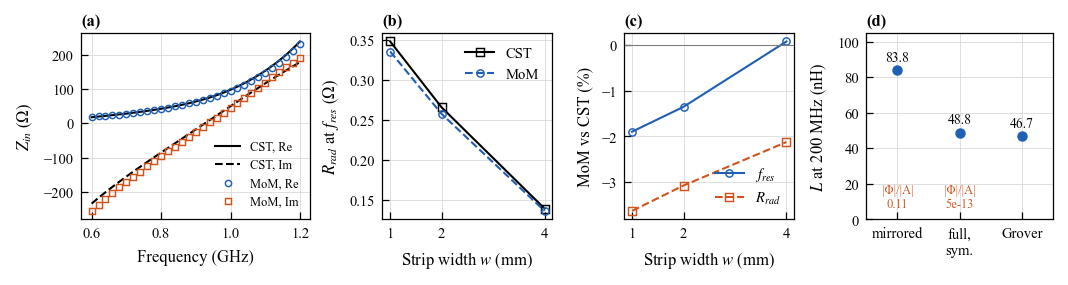

V5a at 0.9 GHz: MoM 62.47-25.80j, CST 63.07-18.35j; resonance MoM 0.9366 / CST 0.9272 GHz
V5b' w = 1 mm: f_res 0.8787 / 0.8957 GHz, R_rad 0.335 / 0.348 Ohm
V5b' w = 2 mm: f_res 0.8800 / 0.8921 GHz, R_rad 0.257 / 0.265 Ohm
V5b' w = 4 mm: f_res 0.8855 / 0.8848 GHz, R_rad 0.136 / 0.139 Ohm


In [4]:
CST5 = cv.load_cst(V5_DIR)
MOM5 = {c['meta']['case']: c for c in cv.load_mom(V5_DIR / 'mom')}
v5a = MOM5['V5a_dipole_nl60_nw4_cosine']
fa, za = CST5['V5a']['zin']
fm = v5a['data']['freq_GHz']; zm = v5a['data']['Re_Zin_ohm'] + 1j * v5a['data']['Im_Zin_ohm']
sel = (fa >= fm.min() * 1e9 - 1) & (fa <= fm.max() * 1e9 + 1)
z_cst_m = np.interp(fm * 1e9, fa, za.real) + 1j * np.interp(fm * 1e9, fa, za.imag)
k09 = int(np.argmin(np.abs(fm - 0.9)))
dre = 100 * (zm[k09].real / z_cst_m[k09].real - 1); dim_ = zm[k09].imag - z_cst_m[k09].imag
res_m, res_c = cv.cst_resonance((fm * 1e9, zm)), cv.cst_resonance((fa, za))

cst_res = cv.cst_v5bp_resonances(CST5)
rows_bp = []
for w in (1.0, 2.0, 4.0):
    r = {(row['mode'], row['variant']): row for row in MOM5[f'V5bp_cst_w{w:g}mm_ns16_nw4_cosine']['resonance']}
    rows_bp.append(dict(w=w, f_mom=r[('C_cst', 'PEC')]['f_res_GHz'], f_cst=cst_res[('pec', w)][0] / 1e9,
                        r_mom=r[('C_tuned', 'PEC')]['R_in_exact_ohm'], r_cst=cst_res[('pec', w)][1]))
DIAG = read_json(V5_DIR / 'figures' / 'V5bp_reactance_diagnostic.json')
pc = DIAG['phi_cancellation_and_full_fill']['ns16_nw2']
lg = DIAG['references']['L_grover_nH']
f_low = min(pc['L_full_fill_sym_nH'], key=float)
L_mir, L_sym = pc['L_mirrored_nH'][f_low], pc['L_full_fill_sym_nH'][f_low]
leak_mir, leak_sym = pc['phi_over_A_on_solenoidal']['mirrored (default)'], pc['phi_over_A_on_solenoidal']['full fill, symmetrised']

fig, axes = plt.subplots(1, 4, figsize=(COL2, 1.95), gridspec_kw=dict(width_ratios=[1.35, 1, 1, 1.1]))
ax = axes[0]
ax.plot(fa[sel] / 1e9, za.real[sel], color=BLACK, lw=1.0, label='CST, Re')
ax.plot(fa[sel] / 1e9, za.imag[sel], color=BLACK, lw=1.0, ls='--', label='CST, Im')
ax.plot(fm, zm.real, 'o', color=BLUE, mfc='none', mew=0.7, ms=3, label='MoM, Re')
ax.plot(fm, zm.imag, 's', color=ORANGE, mfc='none', mew=0.7, ms=3, label='MoM, Im')
ax.set_xlabel('Frequency (GHz)'); ax.set_ylabel('$Z_{in}$ (Ω)'); ax.legend(loc='lower right', fontsize=6, ncol=1)
panel(ax, 'a')
ax = axes[1]
w_ = [r['w'] for r in rows_bp]
ax.plot(w_, [r['r_cst'] for r in rows_bp], 's-', color=BLACK, mfc='none', mew=0.7, label='CST')
ax.plot(w_, [r['r_mom'] for r in rows_bp], 'o--', color=BLUE, mfc='none', mew=0.7, label='MoM')
ax.set_xlabel('Strip width $w$ (mm)'); ax.set_ylabel('$R_{rad}$ at $f_{res}$ (Ω)'); ax.legend(loc='upper right')
ax.set_xticks(w_); panel(ax, 'b')
ax = axes[2]
ax.plot(w_, [100 * (r['f_mom'] / r['f_cst'] - 1) for r in rows_bp], 'o-', color=BLUE, mfc='none', mew=0.7, label='$f_{res}$')
ax.plot(w_, [100 * (r['r_mom'] / r['r_cst'] - 1) for r in rows_bp], 's--', color=ORANGE, mfc='none', mew=0.7,
        label='$R_{rad}$')
ax.axhline(0, color=GREY, lw=0.5)
ax.set_xlabel('Strip width $w$ (mm)'); ax.set_ylabel('MoM vs CST (%)'); ax.legend(loc='best'); ax.set_xticks(w_)
panel(ax, 'c')
ax = axes[3]
labs = ['mirrored', 'full,\nsym.', 'Grover']
vals = [L_mir, L_sym, lg]
ax.plot([0, 1, 2], vals, 'o', color=BLUE, ms=4)
for k, v in enumerate(vals):
    ax.text(k, v + 0.04 * max(vals), f'{v:.1f}', ha='center', va='bottom', fontsize=6.5)
ax.text(0, 0.06 * max(vals), f'|Φ|/|A|\n{leak_mir:.2f}', ha='center', va='bottom', fontsize=6, color=ORANGE)
ax.text(1, 0.06 * max(vals), f'|Φ|/|A|\n{leak_sym:.0e}', ha='center', va='bottom', fontsize=6, color=ORANGE)
ax.set_xticks([0, 1, 2], labs); ax.set_xlim(-0.5, 2.5); ax.set_ylim(0, max(vals) * 1.25)
ax.set_ylabel(f'$L$ at {float(f_low) / 1e6:.0f} MHz (nH)'); panel(ax, 'd')
fig.tight_layout(w_pad=0.6)
save(fig, 'fig03_solver_validation',
     f"Validation of the MoM solver against CST and theory. (a) PEC strip dipole 150 × 4 mm: input impedance, "
     f"MoM (delta gap, {v5a['meta']['n_edges']} RWG edges) vs CST (0.5-mm gap edge port); at 0.9 GHz "
     f"Re Z differs by {dre:+.1f} % and Im Z by {dim_:+.1f} Ω; series resonance {res_m[0] / 1e9:.3f} GHz (MoM) vs "
     f"{res_c[0] / 1e9:.3f} GHz (CST). (b, c) Capacitively tuned small loop (outer side "
     f"{1e3 * DIAG['side_m'] + 0:g} mm), PEC: radiation resistance at resonance and relative MoM–CST differences of "
     f"f_res and R_rad versus strip width. (d) Correction of the Z assembly: mirroring the upper triangle leaked "
     f"{100 * leak_mir:.0f} % of the scalar-potential term into solenoidal (loop) currents; the symmetrised full fill "
     f"removes it ({leak_sym:.0e}) and the static loop inductance moves from {L_mir:.1f} to {L_sym:.1f} nH "
     f"(Grover: {lg:.1f} nH).",
     [V5_DIR / 'mom' / 'V5a_dipole_nl60_nw4_cosine' / 'results.csv', V5_DIR / 'V5a' / 'Dipole ruban PEC.s1p',
      V5_DIR / 'mom', V5_DIR / "V5b'", V5_DIR / 'figures' / 'V5bp_reactance_diagnostic.json'])
print(f'V5a at 0.9 GHz: MoM {zm[k09]:.2f}, CST {z_cst_m[k09]:.2f}; resonance MoM {res_m[0] / 1e9:.4f} / CST {res_c[0] / 1e9:.4f} GHz')
for r in rows_bp:
    print(f"V5b' w = {r['w']:g} mm: f_res {r['f_mom']:.4f} / {r['f_cst']:.4f} GHz, R_rad {r['r_mom']:.3f} / {r['r_cst']:.3f} Ohm")

## Fig. 4 — MoM contre CST, design B3 dans l'air (V6a)

MoM : `V6_expected_B3_1.00GHz_freq.csv` (composants figés, Z recalculé à chaque fréquence). CST V6a : `.s1p`
(Z_in) et coupes θ = 90° (G(+y), composante φ) à 0,99 / 1,00 / 1,01 GHz.

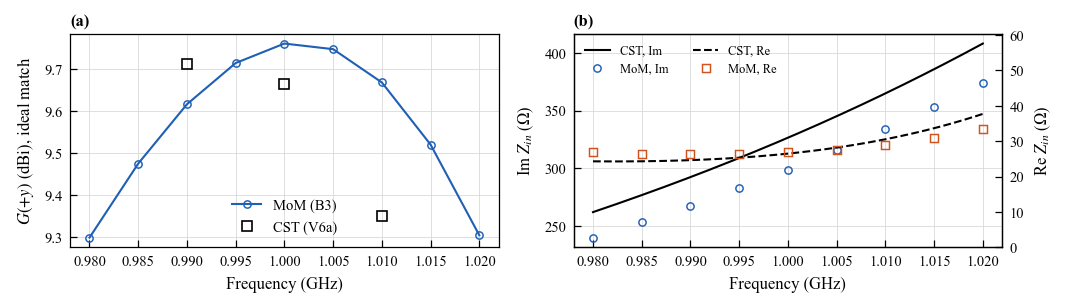

In [5]:
FREQ = read_csv(V6_DIR / 'V6_expected_B3_1.00GHz_freq.csv')
f_mom = np.array([r['f_GHz'] for r in FREQ])
g_mom = np.array([r['G_dBi'] for r in FREQ])
z_mom = np.array([r['Zin_re_ohm'] + 1j * r['Zin_im_ohm'] for r in FREQ])
S1P_V6A = V6_DIR / 'V6a' / 'Reseau end-fire.s1p'
d6a = mfc.read_s1p(S1P_V6A)
cuts6a = cuts_by_freq(V6_DIR / 'V6a')
g6a = {f: cut_value(p, 90.0) for f, p in cuts6a.items()}
sel = (d6a['f_hz'] >= 0.98e9 - 1) & (d6a['f_hz'] <= 1.02e9 + 1)
SH = read_json(V6_DIR / 'V6a' / 'adaptation_from_cst_johanson.json')['gain']['shift']['s']

fig, axes = plt.subplots(1, 2, figsize=(COL2, 2.1))
ax = axes[0]
ax.plot(f_mom, g_mom, 'o-', color=BLUE, mfc='none', mew=0.7, label='MoM (B3)')
ax.plot(list(g6a), list(g6a.values()), 's', color=BLACK, mfc='none', mew=0.8, ms=4.5, label='CST (V6a)')
ax.set_xlabel('Frequency (GHz)'); ax.set_ylabel('$G(+y)$ (dBi), ideal match'); ax.legend(loc='lower center')
panel(ax, 'a')
ax = axes[1]
ax.plot(d6a['f_hz'][sel] / 1e9, d6a['z'][sel].imag, color=BLACK, label='CST, Im')
ax.plot(f_mom, z_mom.imag, 'o', color=BLUE, mfc='none', mew=0.7, label='MoM, Im')
ax2 = ax.twinx()
ax2.plot(d6a['f_hz'][sel] / 1e9, d6a['z'][sel].real, color=BLACK, ls='--', label='CST, Re')
ax2.plot(f_mom, z_mom.real, 's', color=ORANGE, mfc='none', mew=0.7, label='MoM, Re')
ax.set_xlabel('Frequency (GHz)'); ax.set_ylabel('Im $Z_{in}$ (Ω)'); ax2.set_ylabel('Re $Z_{in}$ (Ω)')
ax2.grid(False); ax2.set_ylim(0, max(d6a['z'][sel].real.max(), z_mom.real.max()) * 1.6)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper left', ncol=2, fontsize=6)
panel(ax, 'b')
fig.tight_layout(w_pad=1.0)
z1 = d6a['z'][np.argmin(np.abs(d6a['f_hz'] - 1e9))]
save(fig, 'fig04_mom_vs_cst_air',
     f"Design B3 in free space (no substrate), MoM vs CST (V6a). (a) End-fire gain towards +y with ideal matching "
     f"(φ polarisation): {g_mom[np.argmin(np.abs(f_mom - 1))]:.2f} dBi (MoM) vs {g6a[1.0]:.2f} dBi (CST) at 1 GHz. "
     f"(b) Input impedance of the fed strip: at 1 GHz {z_mom[np.argmin(np.abs(f_mom - 1))].real:.1f} + "
     f"j{z_mom[np.argmin(np.abs(f_mom - 1))].imag:.0f} Ω (MoM) vs {z1.real:.1f} + j{z1.imag:.0f} Ω (CST); the CST "
     f"reactance equals the MoM one at a frequency {100 * SH:.2f} % lower (equal-reactance offset).",
     [V6_DIR / 'V6_expected_B3_1.00GHz_freq.csv', S1P_V6A, *cuts6a.values(), V6_DIR / 'V6a' / 'adaptation_from_cst_johanson.json'])

## Fig. 5 — Effet du substrat et recentrage

Pour chaque dossier `V6b_balayage_X/X=…` et pour `V6b` (X = 90 mm, sur substrat) : G(+y) (coupe θ = 90°,
φ = 90°, composante φ) aux trois fréquences, Z_in à 1 GHz (`.s1p`) et efficacité de rayonnement. Référence dans
l'air : V6a (X = 90 mm).

 X (mm)   G(+y) 0.99/1.00/1.01 (dBi) G(-y) 1.00        Z_in(1 GHz) eta_rad
  72.50     7.18     7.88     8.48       2.52    26.8  +178.5j   94.6 %
  75.00     8.59     9.02     9.22       3.49    24.5  +257.1j   91.3 %
  76.25     9.23     9.38     9.27       2.91    28.0  +297.5j   91.7 %
  77.50     9.24     8.86     8.22       4.34    39.2  +393.5j   91.1 %
  80.00     7.64     6.77     5.91       5.11    82.5  +561.4j   93.0 %
  82.50     6.66     5.78     4.98       5.07   139.7  +706.2j   94.3 %
  90.00     2.53     2.35     2.22       3.94  2267.4  -256.8j   97.5 %


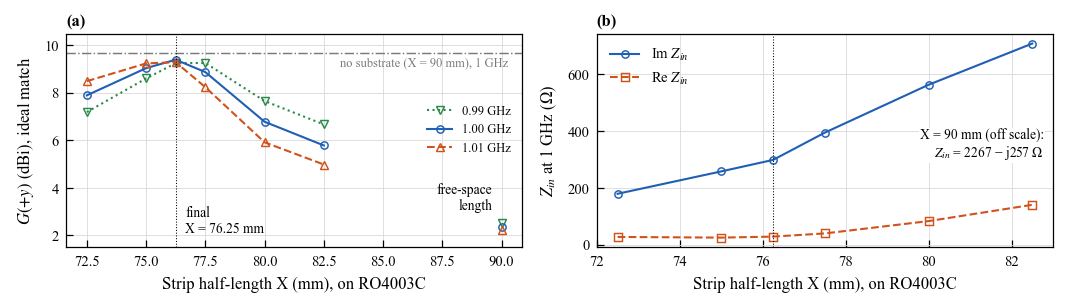

In [6]:
CASES = []
for d in sorted([p for p in SWEEP_DIR.iterdir() if p.is_dir() and p.name.startswith('X=')] + [V6_DIR / 'V6b'],
                key=lambda p: cst_params(next(p.glob('*.s1p')))['X']):
    s1p = next(d.glob('*.s1p'))
    X = cst_params(s1p)['X']
    data = mfc.read_s1p(s1p)
    z1 = complex(np.interp(1e9, data['f_hz'], data['z'].real) + 1j * np.interp(1e9, data['f_hz'], data['z'].imag))
    cuts = cuts_by_freq(d)
    eff_p = next(d.glob('*Rad_Efficiency.txt'))
    fe, eta = cv.read_cst_efficiency(eff_p)
    CASES.append(dict(X=X, folder=d, s1p=s1p, z1=z1, G={f: cut_value(p, 90.0) for f, p in cuts.items()},
                      Gtot={f: cut_value(p, 90.0, 'Abs(Gain)') for f, p in cuts.items()},
                      Gback={f: cut_value(p, 270.0) for f, p in cuts.items()},
                      eta1=float(np.interp(1e9, fe, eta)), cuts=list(cuts.values()), eff=eff_p))
G_AIR = cut_value(cuts6a[1.0], 90.0)
print(f"{'X (mm)':>7} {'G(+y) 0.99/1.00/1.01 (dBi)':>28} {'G(-y) 1.00':>10} {'Z_in(1 GHz)':>18} {'eta_rad':>7}")
for c in CASES:
    print(f"{c['X']:7.2f} {c['G'][0.99]:8.2f} {c['G'][1.0]:8.2f} {c['G'][1.01]:8.2f}   {c['Gback'][1.0]:8.2f} "
          f"{c['z1'].real:7.1f} {c['z1'].imag:+7.1f}j {100 * c['eta1']:6.1f} %")

# values quoted in the step-9 / step-10 instructions (checked against the files)
QUOTED = {72.5: ((7.18, 7.88, 8.48), 26.8 + 178j), 75.0: ((8.59, 9.02, 9.22), 24.5 + 257j),
          77.5: ((9.24, 8.86, 8.22), 39.2 + 394j), 80.0: ((7.64, 6.77, 5.91), 82.5 + 561j),
          82.5: ((6.66, 5.78, 4.98), 140 + 706j)}
for c in CASES:
    if c['X'] in QUOTED:
        g, z = QUOTED[c['X']]
        check(f"X = {c['X']:g} : G(+y) 0,99/1/1,01 cités (étape 10) vs coupes CST", list(g),
              [c['G'][0.99], c['G'][1.0], c['G'][1.01]], 0.006, 'dB')
        check(f"X = {c['X']:g} : Z_in(1 GHz) cité vs .s1p", z, c['z1'], 1.0, 'Ω')
c90 = next(c for c in CASES if c['X'] == 90.0)
check('V6b (X = 90) : G(+y) = 2,35 dBi cité (étape 9)', 2.35, c90['G'][1.0], 0.006, 'dB')
check('V6b (X = 90) : G(−y) = 3,94 dBi cité (étape 9)', 3.94, c90['Gback'][1.0], 0.006, 'dB')

fig, axes = plt.subplots(1, 2, figsize=(COL2, 2.1))
ax = axes[0]
SW = [c for c in CASES if c['folder'].parent == SWEEP_DIR]          # sweep cases (lines); X = 90 (V6b): markers only
Xs = [c['X'] for c in SW]
for f, mk, col, ls in ((0.99, 'v', GREEN, ':'), (1.0, 'o', BLUE, '-'), (1.01, '^', ORANGE, '--')):
    ax.plot(Xs, [c['G'][f] for c in SW], marker=mk, ls=ls, color=col, mfc='none', mew=0.7, label=f'{f:.2f} GHz')
    ax.plot([c90['X']], [c90['G'][f]], marker=mk, ls='none', color=col, mfc='none', mew=0.7)
ax.axhline(G_AIR, color=GREY, lw=0.7, ls='-.')
ax.text(90.3, G_AIR - 0.15, 'no substrate (X = 90 mm), 1 GHz', color=GREY, fontsize=6, ha='right', va='top')
xf = P_FINAL['X']
ax.axvline(xf, color=BLACK, lw=0.5, ls=':')
ax.set_ylim(1.5, G_AIR + 0.8)
ax.text(xf + 0.4, 2.0, f'final\nX = {xf:g} mm', fontsize=6.5, va='bottom')
ax.text(c90['X'] - 0.4, c90['G'][1.0] + 0.6, 'free-space\nlength', fontsize=6.5, ha='right', va='bottom')
ax.set_xlabel('Strip half-length X (mm), on RO4003C'); ax.set_ylabel('$G(+y)$ (dBi), ideal match')
ax.legend(loc='center right', bbox_to_anchor=(1.0, 0.55), fontsize=6); panel(ax, 'a')
ax = axes[1]
ax.plot(Xs, [c['z1'].imag for c in SW], 'o-', color=BLUE, mfc='none', mew=0.7, label='Im $Z_{in}$')
ax.plot(Xs, [c['z1'].real for c in SW], 's--', color=ORANGE, mfc='none', mew=0.7, label='Re $Z_{in}$')
ax.axvline(xf, color=BLACK, lw=0.5, ls=':')
ax.text(0.98, 0.04, f'X = 90 mm (off scale):\n$Z_{{in}}$ = {c90["z1"].real:.0f} − j{-c90["z1"].imag:.0f} Ω',
        transform=ax.transAxes, ha='right', va='bottom', fontsize=6.5,
        bbox=dict(fc='white', ec='none', pad=0.5)).set_position((0.98, 0.40))
ax.set_xlabel('Strip half-length X (mm), on RO4003C'); ax.set_ylabel('$Z_{in}$ at 1 GHz (Ω)')
ax.legend(loc='upper left'); panel(ax, 'b')
fig.tight_layout(w_pad=1.0)
cf = next(c for c in CASES if c['X'] == xf)
save(fig, 'fig05_substrate_retuning',
     f"Effect of the RO4003C board and re-centring. With the free-space lengths (X = 90 mm) the board detunes the array: "
     f"G(+y) falls from {G_AIR:.2f} dBi (no substrate) to {c90['G'][1.0]:.2f} dBi and the main lobe turns to −y "
     f"(G(−y) = {c90['Gback'][1.0]:.2f} dBi), while the radiation efficiency stays {100 * c90['eta1']:.1f} %. "
     f"(a) End-fire gain versus strip half-length (loads unchanged, 0.5 / 1 pF); (b) input impedance of the fed strip at "
     f"1 GHz. The final length X = {xf:g} mm gives {cf['G'][1.0]:.2f} dBi at 1 GHz and "
     f"Z_in = {cf['z1'].real:.1f} + j{cf['z1'].imag:.0f} Ω.",
     [*(c['s1p'] for c in CASES), *(p for c in CASES for p in c['cuts']), *(c['eff'] for c in CASES), cuts6a[1.0]])

## Fig. 6 — Design final (CST, substrat)

Coupes de gain à f₀ : plan xy (`farfield_cut_theta=90_f=1GHz.txt`) et plan yz (φ = 90° et 270° du champ lointain 3D
`farfield_f=1GHz.txt`, pas de 5°) ; G(+y) aux trois fréquences exportées ; efficacité de rayonnement.

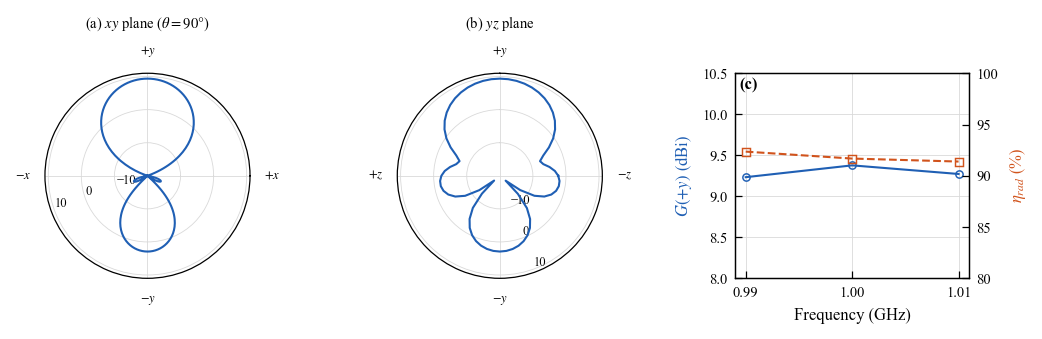

In [7]:
cut_xy = cv.read_cst_farfield(FINAL_DIR / 'farfield_cut_theta=90_f=1GHz.txt')
ff3d = cv.read_cst_farfield(FINAL_DIR / 'farfield_f=1GHz.txt')
th, ph = ff3d['Theta'], ff3d['Phi']
up, dn = np.isclose(ph, 90.0), np.isclose(ph, 270.0)
# yz plane, angle psi from +y towards +z: phi = 90 -> psi = 90 - theta ; phi = 270 -> psi = 90 + theta
psi = np.concatenate([90 - th[up], 90 + th[dn]]); gyz = np.concatenate([ff3d['Abs(Gain)'][up], ff3d['Abs(Gain)'][dn]])
o = np.argsort(psi); psi, gyz = psi[o], gyz[o]
cf = next(c for c in CASES if c['X'] == P_FINAL['X'])
k_py = int(np.argmin(np.abs(cut_xy['Phi'] - 90)))
check('coupe xy : G(+y) total = valeur du 3D (θ = 90°, φ = 90°)', cut_xy['Abs(Gain)'][k_py],
      ff3d['Abs(Gain)'][np.isclose(th, 90) & up][0], 0.01, 'dB')
gmax = max(cut_xy['Abs(Gain)'].max(), gyz.max())
floor = np.ceil(gmax) - 30
fb = cf['G'][1.0] - cf['Gback'][1.0]

fig = plt.figure(figsize=(COL2, 2.25))
axa = fig.add_subplot(1, 3, 1, projection='polar'); axb = fig.add_subplot(1, 3, 2, projection='polar')
axc = fig.add_subplot(1, 3, 3)
for ax, ang, g, lab in ((axa, np.radians(cut_xy['Phi']), cut_xy['Abs(Gain)'], 'xy'), (axb, np.radians(psi), gyz, 'yz')):
    ax.plot(np.append(ang, ang[0]), np.maximum(np.append(g, g[0]), floor), color=BLUE, lw=1.0)
    ax.set_theta_zero_location('N'); ax.set_theta_direction(1 if lab == 'yz' else 1)
    ax.set_rlim(floor, np.ceil(gmax) + 1); ax.set_rticks(np.arange(floor + 10, np.ceil(gmax) + 1, 10))
    ax.tick_params(labelsize=6); ax.grid(lw=0.4)
    ax.set_rlabel_position(200)
axa.set_theta_offset(0)                                         # phi: 0 deg = +x at the right, +y up
axa.set_theta_zero_location('E')
axa.set_xticks(np.radians([0, 90, 180, 270]), ['$+x$', '$+y$', '$-x$', '$-y$'])
axb.set_theta_zero_location('N')                               # psi: 0 = +y up, +z to the left
axb.set_xticks(np.radians([0, 90, 180, 270]), ['$+y$', '$+z$', '$-y$', '$-z$'])
axa.set_title('(a) $xy$ plane ($\\theta = 90°$)', fontsize=7, pad=8)
axb.set_title('(b) $yz$ plane', fontsize=7, pad=8)
fs = sorted(cf['G'])
axc.plot(fs, [cf['G'][f] for f in fs], 'o-', color=BLUE, mfc='none', mew=0.7, label='$G(+y)$')
axc.set_xlabel('Frequency (GHz)'); axc.set_ylabel('$G(+y)$ (dBi)', color=BLUE)
fe, eta = cv.read_cst_efficiency(cf['eff'])
axr = axc.twinx(); axr.grid(False)
axr.plot(fe / 1e9, 100 * eta, 's--', color=ORANGE, mfc='none', mew=0.7, label='$\\eta_{rad}$')
axr.set_ylabel('$\\eta_{rad}$ (%)', color=ORANGE); axr.set_ylim(80, 100)
axc.set_ylim(np.floor(min(cf['G'].values())) - 1, np.ceil(max(cf['G'].values())) + 0.5)
axc.set_xticks(fs); axc.text(0.02, 0.98, '(c)', transform=axc.transAxes, va='top', fontweight='bold')
fig.tight_layout(w_pad=1.6)
save(fig, 'fig06_final_design_cst',
     f"Final design on RO4003C (CST, X = {P_FINAL['X']:g} mm, loads 0.5 / 1 pF), gain with ideal matching. (a) xy-plane "
     f"and (b) yz-plane gain cuts at 1 GHz (total gain, dBi, 10 dB/div); G(+y) = {cf['Gtot'][1.0]:.2f} dBi, "
     f"front-to-back ratio G(+y)/G(−y) = {fb:.1f} dB. (c) G(+y) (φ polarisation) at the three exported frequencies and "
     f"radiation efficiency ({100 * float(np.interp(1e9, fe, eta)):.1f} % at 1 GHz: copper and dielectric losses).",
     [FINAL_DIR / 'farfield_cut_theta=90_f=1GHz.txt', FINAL_DIR / 'farfield_f=1GHz.txt', *cf['cuts'], cf['eff']])

## Fig. 7 — Adaptation

Réseau retenu dans `adaptation_from_cst_johanson.json` du cas final (rang recommandé), composants Johanson (ESR, ESL
jtisoft), Z_A du `.s1p` CST et G_A du CSV des coupes CST. Sans réseau : G_r = G_A (1 − |Γ|²). G_r n'est tracé que
là où G_A est connu (0,99–1,01 GHz).

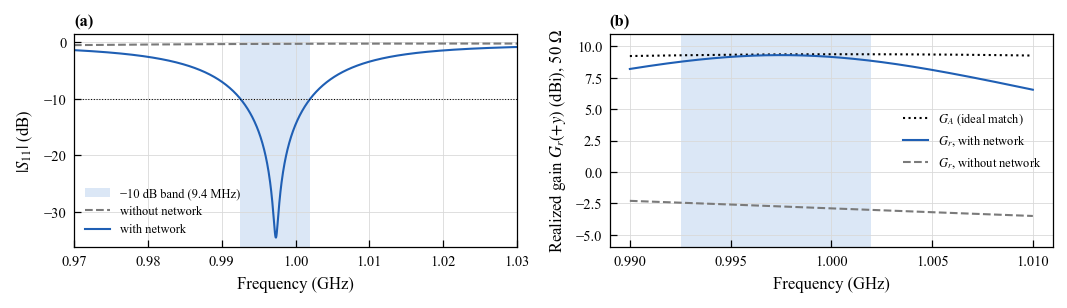

In [8]:
d_fin = mfc.read_s1p(S1P_FINAL)
GCSV = FINAL_DIR / 'gain_plus_y_from_cuts.csv'
ant, ant_z, _ = mfc.build_antennas(d_fin['f_hz'], d_fin['z'], F0, gain_csv=GCSV)
CAP = johanson_r14s_model()
from solver.optim.components import InductorModel
IND = InductorModel(q=ADAPT['models']['inductor']['q'], c_par=ADAPT['models']['inductor']['c_par_pF'] * 1e-12)
net = mfc.network_from_record(sol)
f_s = np.linspace(0.97e9, 1.03e9, 1201)
f_g = np.linspace(ant.f_min, ant.f_max, 401)
r_s = mt.network_response(net, f_s, ant_z, CAP, IND)
r_g = mt.network_response(net, f_g, ant, CAP, IND)
zA_s = ant_z.zin(f_s); gam_s = (zA_s - 50) / (zA_s + 50)
zA_g = ant.zin(f_g); gam_g = (zA_g - 50) / (zA_g + 50)
band = sol['expected']['band']
check('G_r(f0) recalculé = JSON (rang retenu)', float(db(mt.network_response(net, F0, ant, CAP, IND)['G_r'])),
      sol['expected']['G_r_nominal_dBi'], 1e-6, 'dB')
check('|S11(f0)| recalculé = JSON', float(20 * np.log10(abs(mt.network_response(net, F0, ant_z, CAP, IND)['s11']))),
      sol['expected']['S11_dB'], 1e-6, 'dB')

fig, axes = plt.subplots(1, 2, figsize=(COL2, 2.1))
ax = axes[0]
ax.axvspan(band['f_lo_GHz'], band['f_hi_GHz'], color='#dbe7f6', lw=0, label=f"−10 dB band ({band['bw_MHz']:.1f} MHz)")
ax.plot(f_s / 1e9, 20 * np.log10(np.abs(gam_s)), color=GREY, ls='--', label='without network')
ax.plot(f_s / 1e9, 20 * np.log10(np.abs(r_s['s11'])), color=BLUE, label='with network')
ax.axhline(-10, color=BLACK, lw=0.5, ls=':')
ax.set_xlabel('Frequency (GHz)'); ax.set_ylabel('$|S_{11}|$ (dB)'); ax.set_xlim(f_s[0] / 1e9, f_s[-1] / 1e9)
ax.legend(loc='lower left', fontsize=6); panel(ax, 'a')
ax = axes[1]
ax.axvspan(band['f_lo_GHz'], band['f_hi_GHz'], color='#dbe7f6', lw=0)
ax.plot(f_g / 1e9, db(ant.gain(f_g)), color=BLACK, ls=':', label='$G_A$ (ideal match)')
ax.plot(f_g / 1e9, db(r_g['G_r']), color=BLUE, label='$G_r$, with network')
ax.plot(f_g / 1e9, db(ant.gain(f_g) * (1 - np.abs(gam_g) ** 2)), color=GREY, ls='--', label='$G_r$, without network')
ax.set_xlabel('Frequency (GHz)'); ax.set_ylabel('Realized gain $G_r(+y)$ (dBi), 50 Ω')
ax.set_ylim(-6, 11); ax.legend(loc='center right', fontsize=6); panel(ax, 'b')
ax.set_xticks(np.arange(0.990, 1.0101, 0.005))
fig.tight_layout(w_pad=1.0)
els = sol['elements_port_to_gap']
parts = {r.value_pf: r for r in JOHANSON_R14S_RF_1GHZ}
desc = (f"shunt {els[0]['label']} on the port, then {els[1]['label']} and {els[2]['label']} in series, one in each arm "
        f"of the fed strip")
g0 = float(db(ant.gain(F0)))
save(fig, 'fig07_matching',
     f"Lumped matching network on the final CST model ({desc}; Johanson S-series 0603 parts with their 1-GHz ESR/ESL). "
     f"(a) |S11| without and with the network; −10 dB band {band['f_lo_GHz']:.4f}–{band['f_hi_GHz']:.4f} GHz "
     f"({band['bw_MHz']:.1f} MHz, {band['bw_pct']:.2f} %). (b) Realized gain towards +y on 50 Ω: "
     f"{sol['expected']['G_r_nominal_dBi']:.2f} dBi at 1 GHz with the network ({g0:.2f} dBi with ideal matching; "
     f"network loss {sol['expected']['network_loss_dB']:.2f} dB, mismatch {-sol['expected']['mismatch_dB']:.2f} dB) "
     f"vs {float(db(ant.gain(F0) * (1 - abs((ant.zin(F0) - 50) / (ant.zin(F0) + 50)) ** 2))):.2f} dBi without. "
     f"Circuit calculation from the CST impedance and gain (gain exported at 0.99, 1.00 and 1.01 GHz only).",
     [S1P_FINAL, GCSV, FINAL_DIR / 'adaptation_from_cst_johanson.json', *(Path(r.source) for r in JOHANSON_R14S_RF_1GHZ)])

## Fig. 8 — 2, 3 ou 4 éléments, et gain normal de Harrington

Même sélection que `exploration_3_4_elements.ipynb` : meilleur design (élément alimenté optimal) par nombre
d'éléments et par f₀ ; 2 éléments : balayage A (charges continues) ; 3 : grille B3 ; 4 : optimisation bayésienne B4
(à 1,0 GHz seulement). MoM, espace libre, adaptation idéale.

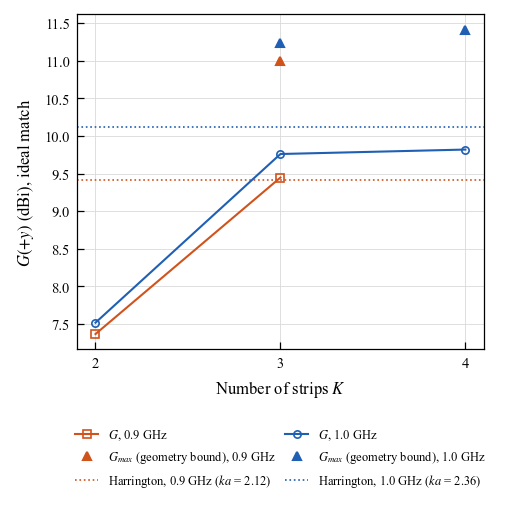

In [9]:
C0 = 1 / np.sqrt(8.854e-12 * 1.257e-6)
BOX_A = np.hypot(W_BOX / 2, L_BOX / 2) * 1e-3
def harrington_db(f_ghz):
    ka = 2 * np.pi * f_ghz * 1e9 / C0 * BOX_A
    return float(10 * np.log10(ka ** 2 + 2 * ka)), ka
A2 = read_csv(EXPL_DIR / 'sweepA_w4mm.csv')
CMP = []
for f in (0.9, 1.0):
    a2 = [r for r in A2 if r['alpha_factor'] == 1.0 and r['best_config'] is True and abs(r['f_GHz'] - f) < 1e-9]
    if a2:
        b = max(a2, key=lambda r: r['G'])
        CMP.append(dict(K=2, f0=f, G=b['G_dBi'], Gmax=np.nan))
    for recs in (B3, B4):
        best = [r for r in recs if r['best_fed'] and abs(r['f0_GHz'] - f) < 1e-9]
        if best:
            b = max(best, key=lambda r: r['objective'])
            CMP.append(dict(K=b['n_elements'], f0=f, G=b['G_kit_dBi'], Gmax=b['G_max_dBi']))
b3_1 = next(r for r in CMP if r['K'] == 3 and r['f0'] == 1.0)
check('B3 à 1 GHz : G (B3_designs.jsonl) = paramètres', b3_1['G'], B3P['expected']['G_kit_dBi'], 1e-9, 'dB')

fig, ax = plt.subplots(figsize=(COL1, 2.9))
for f, col, mk in ((0.9, ORANGE, 's'), (1.0, BLUE, 'o')):
    sel = sorted([r for r in CMP if r['f0'] == f], key=lambda r: r['K'])
    ax.plot([r['K'] for r in sel], [r['G'] for r in sel], marker=mk, color=col, mfc='none', mew=0.8, label=f'$G$, {f:.1f} GHz')
    gm = [r for r in sel if np.isfinite(r['Gmax'])]
    ax.plot([r['K'] for r in gm], [r['Gmax'] for r in gm], marker='^', ls='none', color=col, ms=4,
            label=f'$G_{{max}}$ (geometry bound), {f:.1f} GHz')
    gn, ka = harrington_db(f)
    ax.axhline(gn, color=col, ls=':', lw=0.8, label=f'Harrington, {f:.1f} GHz ($ka$ = {ka:.2f})')
ax.set_xticks([2, 3, 4]); ax.set_xlabel('Number of strips $K$'); ax.set_ylabel('$G(+y)$ (dBi), ideal match')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), fontsize=6, ncol=2, columnspacing=0.8, handlelength=1.8)
g1 = harrington_db(1.0)[0]
g09_3 = next(r['G'] for r in CMP if r['K'] == 3 and r['f0'] == 0.9); gn09 = harrington_db(0.9)[0]
save(fig, 'fig08_elements_harrington',
     f"Best end-fire gain (MoM, free space, ideal matching, kit loads) versus number of strips in the box, at 0.9 and "
     f"1.0 GHz, with the geometry bound G_max (optimal currents, losses included) and Harrington's normal gain "
     f"(ka)² + 2ka of the sphere enclosing the box (a = {1e3 * BOX_A:.1f} mm). At 1 GHz, 3 strips give "
     f"{b3_1['G']:.2f} dBi, {g1 - b3_1['G']:.2f} dB below the normal gain ({g1:.2f} dBi); a 4th strip adds "
     f"{next(r['G'] for r in CMP if r['K'] == 4 and r['f0'] == 1.0) - b3_1['G']:.2f} dB. At 0.9 GHz the best 3-strip "
     f"design reaches {g09_3:.2f} dBi, {g09_3 - gn09:+.2f} dB relative to the normal gain ({gn09:.2f} dBi).",
     [EXPL_DIR / 'sweepA_w4mm.csv', EXPL_DIR / 'B3_designs.jsonl', EXPL_DIR / 'B4_designs.jsonl',
      NOTES_DIR / '01_sujet_et_contraintes.md'])

## Index des figures et contrôles de cohérence

In [10]:
from IPython.display import Markdown, display
lines = ['# Report figures — index', '',
         'Generated by `solver/antenna_simulation/euraap_challenge/rapport_figures.ipynb`. Every figure exists as '
         '`<name>.png` (300 dpi) and `<name>.pdf` (vector). All values are read from the result files listed below '
         '(paths relative to the challenge folder, or to the repository when marked `repo:`).', '']
for k, e in enumerate(INDEX, 1):
    lines += [f"## Fig. {k} — `{e['name']}`", '', '**Data sources**', '']
    lines += [f'- `{s}`' for s in e['sources']]
    lines += ['', '**Proposed caption**', '', f"Fig. {k}. {e['caption']}", '']
(FIG_DIR / 'figures_index.md').write_text('\n'.join(lines), encoding='utf-8')
print('wrote', FIG_DIR / 'figures_index.md', f'({len(INDEX)} figures)')
rows = ['| contrôle | écart | tolérance | |', '|---|---|---|---|']
rows += [f"| {c['name']} | {c['diff']:.3g} {c['unit']} | {c['tol']:g} | {'✔' if c['ok'] else '**✘**'} |" for c in COHERENCE]
display(Markdown('\n'.join(rows)))
bad = [c for c in COHERENCE if not c['ok']]
print(f'{len(COHERENCE)} contrôles, {len(bad)} incohérence(s)')
for c in bad:
    print(f"  ✘ {c['name']}: {c['a']} vs {c['b']} (écart {c['diff']:.3g} {c['unit']})")

wrote D:\PhD_Fahdilou_Leat\PUBLICATIONS\7-EurAAP Small Antenna Super-Gain Challenge\rapport\figures\figures_index.md (8 figures)


| contrôle | écart | tolérance | |
|---|---|---|---|
| DXF V6b : bout des bras = X du .s1p V6b | 0 mm | 1e-09 | ✔ |
| DXF : demi-gap = paramètre CST gap | 0 mm | 1e-09 | ✔ |
| DXF : centres des rubans = paramètres B3 (MoM) | 1.78e-15 mm | 1e-06 | ✔ |
| DXF : substrat = boîte (x, y) | 0 mm | 1e-09 | ✔ |
| DXF : largeur des rubans = 2 Y (CST) | 0 mm | 1e-09 | ✔ |
| N (présentation) = N (paramètres B3) | 0  | 0 | ✔ |
| X = 72.5 : G(+y) 0,99/1/1,01 cités (étape 10) vs coupes CST | 0.003 dB | 0.006 | ✔ |
| X = 72.5 : Z_in(1 GHz) cité vs .s1p | 0.459 Ω | 1 | ✔ |
| X = 75 : G(+y) 0,99/1/1,01 cités (étape 10) vs coupes CST | 0.003 dB | 0.006 | ✔ |
| X = 75 : Z_in(1 GHz) cité vs .s1p | 0.0859 Ω | 1 | ✔ |
| X = 77.5 : G(+y) 0,99/1/1,01 cités (étape 10) vs coupes CST | 0.004 dB | 0.006 | ✔ |
| X = 77.5 : Z_in(1 GHz) cité vs .s1p | 0.505 Ω | 1 | ✔ |
| X = 80 : G(+y) 0,99/1/1,01 cités (étape 10) vs coupes CST | 0.003 dB | 0.006 | ✔ |
| X = 80 : Z_in(1 GHz) cité vs .s1p | 0.426 Ω | 1 | ✔ |
| X = 82.5 : G(+y) 0,99/1/1,01 cités (étape 10) vs coupes CST | 0.003 dB | 0.006 | ✔ |
| X = 82.5 : Z_in(1 GHz) cité vs .s1p | 0.365 Ω | 1 | ✔ |
| V6b (X = 90) : G(+y) = 2,35 dBi cité (étape 9) | 0.001 dB | 0.006 | ✔ |
| V6b (X = 90) : G(−y) = 3,94 dBi cité (étape 9) | 0.004 dB | 0.006 | ✔ |
| coupe xy : G(+y) total = valeur du 3D (θ = 90°, φ = 90°) | 0 dB | 0.01 | ✔ |
| G_r(f0) recalculé = JSON (rang retenu) | 0 dB | 1e-06 | ✔ |
| |S11(f0)| recalculé = JSON | 0 dB | 1e-06 | ✔ |
| B3 à 1 GHz : G (B3_designs.jsonl) = paramètres | 0 dB | 1e-09 | ✔ |

22 contrôles, 0 incohérence(s)
